# M3 — Data profile of the M2 database

**Project:** NASA Near-Earth Asteroid Hazard Analysis · **Milestone:** M3 (CLEAN) · **Profile by:** Burak Avşar (`@se-220717054`)

This notebook *looks* at the data before anything is cleaned. It opens `data/asteroids.db` **read-only**, so it cannot change the M2 tables.
Every finding below is backed by the cell that produced it, and every check that found nothing is shown too.

**How to run:** from a fresh build (`python src/load.py`), open this notebook and run all cells top to bottom.
The notebook works whether it is started from the repository root or from `notebooks/`.

Sections follow the M3 brief: row counts and coverage → missing values → distributions → text/categories → identity →
first/last appearance and sequences → rule checks (invalid values) → cross-field checks → unusual values → findings.

In [1]:
import json
import sqlite3
import unicodedata
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DB = ROOT / "data" / "asteroids.db"
RAW = ROOT / "data" / "raw"

# mode=ro: the profile can read the M2 tables but never change them (M3 rule 1)
con = sqlite3.connect("file:" + quote(DB.as_posix()) + "?mode=ro", uri=True)

def q(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

AU_KM = 149_597_870.7  # kilometres in one astronomical unit (IAU 2012)

# The whole tables are small enough to profile in pandas; no SQL is built from strings.
ast = q("SELECT * FROM asteroids")
orb = q("SELECT * FROM orbits")
app = q("SELECT * FROM approaches")
qua = q("SELECT * FROM quarantine")

RETRIEVED = ast["retrieved_at"].max()
TODAY = RETRIEVED[:10]  # 'past' and 'future' approaches are relative to the retrieval date
print("database:", DB.relative_to(ROOT))
print("latest retrieval:", RETRIEVED)

database: data\asteroids.db
latest retrieval: 2026-10-17T13:32:21.602341Z


## 1. Row counts and coverage per entity

The entity is the **asteroid**. Orbits are one-per-asteroid; approaches are many-per-asteroid.
For comparisons we group asteroids by **hazard label** and **orbit class**, and approaches by **orbiting body** and **period**.

In [2]:
pd.DataFrame({
    "table": ["asteroids", "orbits", "approaches", "quarantine"],
    "rows": [len(ast), len(orb), len(app), len(qua)],
})

,table,rows
0,asteroids,5033
1,orbits,5000
2,approaches,150936
3,quarantine,0


In [3]:
# Asteroids by hazard label and orbit class ('none' = no orbit row)
a = ast.merge(orb[["asteroid_key", "orbit_class_type"]], on="asteroid_key", how="left")
a["orbit_class_type"] = a["orbit_class_type"].fillna("none")
pd.crosstab(a["orbit_class_type"], a["is_potentially_hazardous"], margins=True)

is_potentially_hazardous,0,1,All
orbit_class_type,,,
AMO,1918,61,1979
APO,1753,867,2620
ATE,287,107,394
IEO,5,2,7
none,24,9,33
All,3987,1046,5033


In [4]:
# How many approaches does each asteroid have? (unequal coverage makes per-asteroid comparisons unfair)
n_app = app.groupby("asteroid_key").size()
a["n_approaches"] = a["asteroid_key"].map(n_app).fillna(0).astype(int)
a["n_earth"] = a["asteroid_key"].map(app[app["orbiting_body"] == "Earth"].groupby("asteroid_key").size()).fillna(0).astype(int)

coverage = pd.cut(a["n_approaches"], [-1, 0, 1, 10, 100, 10_000], labels=["0", "1", "2-10", "11-100", ">100"])
print("approaches per asteroid: min", a.n_approaches.min(), "| median", int(a.n_approaches.median()), "| max", a.n_approaches.max())
pd.crosstab(coverage, a["orbit_class_type"], margins=True)

approaches per asteroid: min 0 | median 16 | max 473


orbit_class_type,AMO,APO,ATE,IEO,none,All
n_approaches,,,,,,
0,255,48,2,0,0,305
1,186,197,0,1,33,417
2-10,720,517,7,0,0,1244
11-100,815,1733,195,2,0,2745
>100,3,125,190,4,0,322
All,1979,2620,394,7,33,5033


orbiting_body
Earth    106102
Venus     22568
Merc       8569
Juptr      7556
Mars       5793
Moon        348

when
future    84274
past      66662


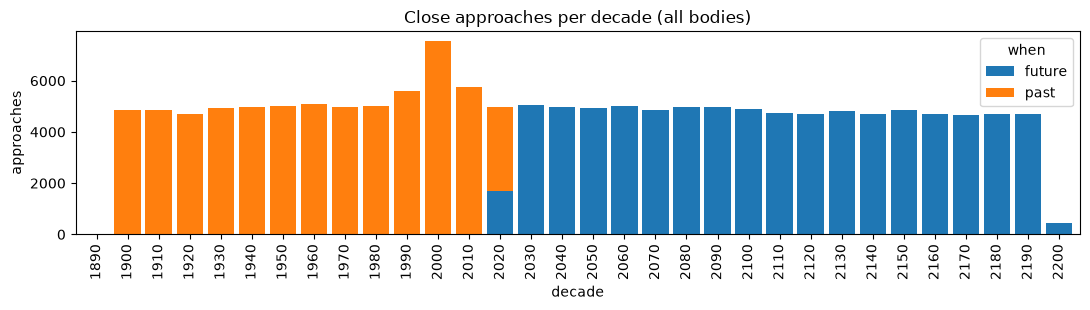

In [5]:
# Approaches per orbiting body and per period (past = before the retrieval date)
app["year"] = app["close_approach_date"].str[:4].astype(int)
app["decade"] = app["year"] // 10 * 10
app["when"] = np.where(app["close_approach_date"] <= TODAY, "past", "future")
print(app["orbiting_body"].value_counts().to_string())
print()
print(app["when"].value_counts().to_string())

per_decade = app.groupby(["decade", "when"]).size().unstack(fill_value=0)
ax = per_decade.plot(kind="bar", stacked=True, figsize=(11, 3.2), width=0.85)
ax.set_title("Close approaches per decade (all bodies)")
ax.set_xlabel("decade")
ax.set_ylabel("approaches")
plt.tight_layout()
plt.show()

**What this shows.** NASA lists approaches in a fixed window, 1900–2200, so more than half of all rows are **predictions**, not observations.
The 2000s have about 50% more approaches than other decades. The first and last decades are partial (the window starts on 1900-01-01 and ends 2200-12-31;
one row is dated 1899-12-31, see section 6).

## 2. Missing values

In [6]:
def missing(df, name):
    m = df.isna().sum()
    return pd.DataFrame({"table": name, "column": m.index, "missing": m.values,
                         "share_%": (100 * m.values / len(df)).round(2)})

miss = pd.concat([missing(ast, "asteroids"), missing(orb, "orbits"),
                  missing(app.drop(columns=["year", "decade", "when"]), "approaches")])
print("columns checked:", len(miss), "| columns with any NULL:", (miss.missing > 0).sum())
miss[miss.missing > 0]

columns checked: 38 | columns with any NULL: 1


,table,column,missing,share_%
3,asteroids,designation,33,0.66


In [7]:
# The missing designations: which raw file shape was each asteroid's kept record loaded from?
import sys
sys.path.insert(0, str(ROOT / "src"))
from load import retrieved_at_from_name  # the loader's own rule: file name -> retrieved_at

shape_of = {retrieved_at_from_name(f): f.name.split("_")[0] for f in RAW.glob("*.json")}
a["has_orbit"] = a["orbit_class_type"] != "none"
a["loaded_from"] = a["retrieved_at"].map(shape_of)
pd.crosstab([a["designation"].isna().rename("designation_missing"), a["has_orbit"]], a["loaded_from"], margins=True)

,loaded_from,browse,feed,lookup,All
designation_missing,has_orbit,,,,
False,True,4894,6,100,5000
True,False,0,33,0,33
All,,4894,39,100,5033


In [8]:
# Evidence: which fields does each raw file shape carry? (feed records have no designation and no orbital_data)
shapes = {}
for f in sorted(RAW.glob("*.json")):
    kind = f.name.split("_")[0]
    if kind in shapes:
        continue
    data = json.loads(f.read_text(encoding="utf-8"))
    neo = data.get("near_earth_objects", [data])
    if isinstance(neo, dict):
        neo = [x for day in neo.values() for x in day]
    shapes[kind] = sorted(neo[0].keys())

fields = sorted(set().union(*shapes.values()))
pd.DataFrame({k: [fld in v for fld in fields] for k, v in shapes.items()}, index=fields)

,browse,feed,lookup
absolute_magnitude_h,True,True,True
close_approach_data,True,True,True
designation,True,False,True
estimated_diameter,True,True,True
id,True,True,True
is_potentially_hazardous_asteroid,True,True,True
is_sentry_object,True,True,True
links,True,True,True
name,True,True,True
name_limited,True,False,True


In [9]:
# Did the loader lose a designation that some raw record does carry? (must be 0)
has_des_in_raw = set()
for f in RAW.glob("*.json"):
    data = json.loads(f.read_text(encoding="utf-8"))
    neo = data.get("near_earth_objects", [data])
    if isinstance(neo, dict):
        neo = [x for day in neo.values() for x in day]
    has_des_in_raw |= {x["id"] for x in neo if x.get("designation")}
lost = ast[ast.designation.isna() & ast.source_id.isin(has_des_in_raw)]
print("NULL designation in the database:", int(ast.designation.isna().sum()))
print("... of which some raw record has a designation (lost by the loader):", len(lost))

NULL designation in the database: 33
... of which some raw record has a designation (lost by the loader): 0


**Finding — missing designation (33 asteroids).** All 33 asteroids without a `designation` were loaded from a **feed** file and appear *only* in feed files,
which do not carry `designation` or `orbital_data` at all — so they also have no orbit row. The value is absent in the source, not lost by us.
* **M2 bug found and fixed here.** The first run of this profile found **39** missing designations: for 6 asteroids an older browse record had the value,
  but the loader keeps the *latest* record per asteroid and a newer feed record (without the field) replaced it.
  `src/load.py` now takes `designation` from the newest record that *has* the field; the cell above checks that no designation present in any raw record is lost (0).
* The designation can be read back from the name: `(2008 TC4)` → `2008 TC4` (section 4 checks this rule on all 5,000 others). The cleaned layer does **not** fill it in
  (no imputation in M3); it flags the value `missing_not_in_source`.

Mechanism: not random — it depends entirely on which endpoint an asteroid was seen in (**MAR on source shape**). Cause **confirmed** by the file contents above.

In [10]:
# Asteroids with no close approach at all, and with no Earth approach
no_app = a[a["n_approaches"] == 0]
no_earth = a[a["n_earth"] == 0]
print("no approach at all:", len(no_app), "| no Earth approach:", len(no_earth))
print()
print(pd.crosstab(no_app["orbit_class_type"], no_app["is_potentially_hazardous"], margins=True))

# Evidence from the raw files: was close_approach_data empty in *every* record of these asteroids?
ids = set(no_app["source_id"])
seen = {"empty": 0, "non-empty": 0}
for f in RAW.glob("*.json"):
    data = json.loads(f.read_text(encoding="utf-8"))
    neo = data.get("near_earth_objects", [data])
    if isinstance(neo, dict):
        neo = [x for day in neo.values() for x in day]
    for x in neo:
        if x.get("id") in ids:
            seen["non-empty" if x.get("close_approach_data") else "empty"] += 1
print()
print("raw records of these asteroids:", seen)

no approach at all: 305 | no Earth approach: 876

is_potentially_hazardous    0  1  All
orbit_class_type                     
AMO                       255  0  255
APO                        41  7   48
ATE                         1  1    2
All                       297  8  305

raw records of these asteroids: {'empty': 326, 'non-empty': 0}


**Finding — asteroids without approaches (305) or without Earth approaches (876).** The source sends an **empty** `close_approach_data` list for all 305
(every one of their 326 raw records), so the loader did not lose them. 255 of the 305 are **Amor** asteroids, whose orbits stay outside Earth's;
they never come close enough, in 1900–2200, to be listed. This is "no event", not "unknown value" — missingness depends on the orbit itself (**MNAR**, inferred).
For M4: an average over approaches silently drops these asteroids, and they are mostly non-hazardous, so per-group approach statistics describe *asteroids that come close*, not all asteroids.

## 3. Distributions: min / median / max per group, and the most frequent values

In [11]:
orb_num = ["eccentricity", "inclination", "semi_major_axis", "perihelion_distance", "aphelion_distance",
           "orbital_period", "minimum_orbit_intersection", "mean_motion"]
orb.groupby("orbit_class_type")[orb_num].agg(["min", "median", "max"]).round(3).T

orbit_class_type                        AMO        APO      ATE      IEO
eccentricity               min        0.016      0.025    0.013    0.305
                           median     0.437      0.536    0.366    0.380
                           max        0.718      0.968    0.895    0.531
inclination                min        0.253      0.122    0.055    2.018
                           median    12.350     11.352   12.812   23.335
                           max       72.156    154.349   56.306   28.263
semi_major_axis            min        1.090      1.001    0.626    0.616
                           median     2.090      1.631    0.891    0.681
                           max        4.271     17.815    0.998    0.741
perihelion_distance        min        1.017      0.070    0.092    0.298
                           median     1.147      0.822    0.557    0.428
                           max        1.300      1.017    0.980    0.502
aphelion_distance          min        1.111      1.068    0.990    0.804
                           median     3.001      2.490    1.175    0.959
                           max        7.292     34.690    1.767    0.980
orbital_period             min      415.598    365.701  180.984  176.563
                           median  1103.535    760.773  307.369  205.421
                           max     3223.643  27463.950  364.051  232.964
minimum_orbit_intersection min        0.006      0.000    0.000    0.008
                           median     0.195      0.039    0.035    0.095
                           max        0.708      0.709    0.356    0.207
mean_motion                min        0.112      0.013    0.989    1.545
                           median     0.326      0.473    1.171    1.752
                           max        0.866      0.984    1.989    2.039

In [12]:
ast.groupby("is_potentially_hazardous")[["absolute_magnitude_h", "diameter_min_km", "diameter_max_km"]] \
   .agg(["min", "median", "max"]).round(3).T

is_potentially_hazardous          0       1
absolute_magnitude_h min      9.170  14.080
                     median  19.770  19.705
                     max     30.100  22.570
diameter_min_km      min      0.003   0.081
                     median   0.295   0.304
                     max     38.954   4.060
diameter_max_km      min      0.006   0.182
                     median   0.661   0.681
                     max     87.104   9.079

In [13]:
app.groupby("orbiting_body")[["miss_distance_km", "relative_velocity_km_s"]] \
   .agg(["count", "min", "median", "max"]).round(2)

miss_distance_km                                         relative_velocity_km_s                    
                         count         min        median           max                  count   min median    max
orbiting_body                                                                                                    
Earth                   106102    12913.14  3.411221e+07  7.479802e+07                 106102  0.13  13.91  63.40
Juptr                     7556  7779369.39  2.464539e+08  2.991885e+08                   7556  0.71   5.91  20.82
Mars                      5793   102197.87  1.041763e+07  1.495566e+07                   5793  0.60  11.62  44.64
Merc                      8569   144394.20  9.865331e+06  1.495752e+07                   8569  3.35  26.96  94.69
Moon                       348    29369.53  9.624384e+05  1.494506e+06                    348  2.04  11.27  39.46
Venus                    22568    71623.24  1.519322e+07  2.243907e+07                  22568  0.12  16.33  83.26

In [14]:
# Most frequent values: sentinels (-999, 0, 9999 ...) hide in the modes and in the extremes
num_cols = {"asteroids": (ast, ["absolute_magnitude_h", "diameter_min_km", "diameter_max_km"]),
            "orbits": (orb, orb_num),
            "approaches": (app, ["miss_distance_km", "relative_velocity_km_s", "epoch_date_close_approach"])}
SENTINELS = [-9999, -999, -99, -1, 0, 99, 999, 9999]
rows = []
for t, (df, cols) in num_cols.items():
    for col in cols:
        vc = df[col].value_counts()
        rows.append({"table": t, "column": col, "distinct": df[col].nunique(),
                     "top_value": vc.index[0], "top_count": vc.iloc[0],
                     "sentinel_hits": int(df[col].isin(SENTINELS).sum()),
                     "negative": int((df[col] < 0).sum())})
pd.DataFrame(rows)

,table,column,distinct,top_value,top_count,sentinel_hits,negative
0,asteroids,absolute_magnitude_h,949,2.440000e+01,34,0,0
1,asteroids,diameter_min_km,949,3.503926e-02,34,0,0
2,asteroids,diameter_max_km,949,7.835018e-02,34,0,0
3,orbits,eccentricity,5000,3.355178e-01,1,0,0
4,orbits,inclination,5000,1.333676e+01,1,0,0
5,orbits,semi_major_axis,5000,1.245804e+00,1,0,0
6,orbits,perihelion_distance,5000,8.278144e-01,1,0,0
7,orbits,aphelion_distance,5000,1.663793e+00,1,0,0
8,orbits,orbital_period,5000,5.078937e+02,1,0,0
9,orbits,minimum_orbit_intersection,4989,1.215520e-01,2,0,0


**Checked, found nothing:** no numeric column contains a sentinel value (−9999, −999, −99, −1, 0, 99, 999, 9999), and the most frequent value
of every measurement column occurs at most 34 times. The only negative values are `epoch_date_close_approach` for approaches before 1970, which is correct
for milliseconds since 1970-01-01.

In [15]:
# Diameter is not measured: it is computed from H
ratio = ast["diameter_max_km"] / ast["diameter_min_km"]
k = ast["diameter_max_km"] * 10 ** (ast["absolute_magnitude_h"] / 5)
print("diameter_max / diameter_min: min %.6f  max %.6f  (sqrt(5) = %.6f)" % (ratio.min(), ratio.max(), 5 ** 0.5))
print("diameter_max * 10^(H/5):     min %.3f  max %.3f" % (k.min(), k.max()))

diameter_max / diameter_min: min 2.236068  max 2.236068  (sqrt(5) = 2.236068)
diameter_max * 10^(H/5):     min 5943.469  max 5943.469


**Finding — diameter is derived from H.** For every asteroid, `diameter_max / diameter_min` is exactly √5 and `diameter × 10^(H/5)` is the same constant.
So both diameters are a fixed function of H (the standard H→D formula with albedo 0.05 and 0.25), not measurements. **Inferred** from the data;
it agrees with the project proposal, which already excludes H and diameter from model features. For M4: diameter adds no information beyond H.

## 4. Text and category values (shown with `repr`)

In [16]:
for t, df, col in [("approaches", app, "orbiting_body"), ("orbits", orb, "orbit_class_type"),
                   ("orbits", orb, "orbit_class_description"), ("orbits", orb, "orbit_class_range"),
                   ("orbits", orb, "orbit_uncertainty")]:
    vc = df[col].value_counts(dropna=False)
    print(f"{t}.{col}: {len(vc)} distinct")
    for v, c in vc.items():
        print(f"    {v!r:<75} {c}")
    print()

approaches.orbiting_body: 6 distinct
    'Earth'                                                                     106102
    'Venus'                                                                     22568
    'Merc'                                                                      8569
    'Juptr'                                                                     7556
    'Mars'                                                                      5793
    'Moon'                                                                      348

orbits.orbit_class_type: 4 distinct
    'APO'                                                                       2620
    'AMO'                                                                       1979
    'ATE'                                                                       394
    'IEO'                                                                       7

orbits.orbit_class_description: 4 distinct
    'Near-Earth asteroid orbits wh

In [17]:
# Hidden differences: Unicode form, non-ASCII, whitespace, case variants, in every text column
text_cols = [("asteroids", ast, "name"), ("asteroids", ast, "designation"), ("approaches", app, "orbiting_body"),
             ("orbits", orb, "orbit_class_type"), ("orbits", orb, "orbit_class_description")]
rows = []
for t, df, col in text_cols:
    s = df[col].dropna()
    rows.append({"column": f"{t}.{col}", "values": len(s),
                 "not_NFC": int((s != s.map(lambda x: unicodedata.normalize("NFC", x))).sum()),
                 "non_ascii": int(s.str.contains(r"[^\x00-\x7f]").sum()),
                 "leading_trailing_space": int((s != s.str.strip()).sum()),
                 "double_space": int(s.str.contains("  ").sum()),
                 "case_variants": int(s.nunique() - s.str.casefold().nunique())})
pd.DataFrame(rows)

,column,values,not_NFC,non_ascii,leading_trailing_space,double_space,case_variants
0,asteroids.name,5033,0,0,0,0,0
1,asteroids.designation,5000,0,0,0,0,0
2,approaches.orbiting_body,150936,0,0,0,0,0
3,orbits.orbit_class_type,5000,0,0,0,0,0
4,orbits.orbit_class_description,5000,0,2620,0,0,0


In [18]:
# Name formats and the designation rule: numbered -> designation is the number; unnumbered -> designation is the text in brackets
fmt = pd.Series(np.select([ast.name.str.fullmatch(r"\d+ \(.+\)"), ast.name.str.fullmatch(r"\(.+\)"),
                           ast.name.str.fullmatch(r"\d+ \S.* \(.+\)")],
                          ["123 (2001 AB)", "(2001 AB)", "123 Name (2001 AB)"], "other"))
print(fmt.value_counts().to_string())

number = ast.name.str.extract(r"^(\d+) ")[0]
bracket = ast.name.str.extract(r"\(([^)]+)\)$")[0]
expected = number.fillna(bracket)
has = ast.designation.notna()
print()
print("designation present:", has.sum(), "| equal to the rule:", (ast.designation[has] == expected[has]).sum())
print("missing designations the rule can recover:", expected[~has].notna().sum(), "of", (~has).sum())

123 (2001 AB)         2746
(2001 AB)             2112
123 Name (2001 AB)     175

designation present: 5000 | equal to the rule: 5000
missing designations the rule can recover: 33 of 33


**Findings — text.**
* `orbiting_body` uses NASA's abbreviations: **`'Merc'`** (Mercury) and **`'Juptr'`** (Jupiter), next to full names (`'Earth'`, `'Venus'`, `'Mars'`, `'Moon'`).
  Not wrong, but inconsistent — a candidate for a mapping table (`data/mappings/`), not for a rename in code.
* `orbit_uncertainty` is NASA's 0–9 *uncertainty parameter*, stored as **text**. It is an ordered code, not a measurement; 74% of orbits have `'0'` (best).
* **Checked, found nothing:** no non-NFC strings, no leading/trailing or double spaces, no case variants in any text column;
  `orbit_class_type` has exactly 4 values, each with one description and one range.
* The only non-ASCII character is the typographic apostrophe `’` (U+2019) in the Apollo description (`Earth’s`), the same in all 2,620 rows — harmless,
  but a plain `'` search would not match it.
* The designation rule holds for all 5,000 asteroids that have one, and would recover all 33 missing ones.

## 5. Identity: is one asteroid recorded twice?

In [19]:
# The text in brackets is the provisional designation; it should belong to exactly one asteroid
dup = ast.assign(prov=bracket).groupby("prov").filter(lambda g: len(g) > 1).sort_values(["prov", "source_id"])
print("provisional designations used by more than one source_id:", dup["prov"].nunique())
pairs = dup.merge(app[["asteroid_key", "close_approach_date_full", "miss_distance_km", "relative_velocity_km_s"]], on="asteroid_key")
pairs[["prov", "source_id", "name", "absolute_magnitude_h", "is_potentially_hazardous",
       "close_approach_date_full", "miss_distance_km", "relative_velocity_km_s", "retrieved_at"]]

provisional designations used by more than one source_id: 3


,prov,source_id,name,absolute_magnitude_h,is_potentially_hazardous,close_approach_date_full,miss_distance_km,relative_velocity_km_s,retrieved_at
0,2008 TC4,2614134,614134 (2008 TC4),21.65,1,2026-10-17T04:02Z,4.555272e+07,25.012639,2026-10-17T13:26:06.808599Z
1,2008 TC4,3430309,(2008 TC4),21.65,1,2026-10-17T04:02Z,4.555272e+07,25.012639,2026-10-17T13:26:06.808599Z
2,2018 EH4,2678976,678976 (2018 EH4),21.68,1,2026-10-14T05:49Z,8.427728e+06,13.222367,2026-10-17T13:26:06.808599Z
3,2018 EH4,3801936,(2018 EH4),21.67,1,2026-10-14T05:49Z,8.427648e+06,13.222378,2026-10-17T13:26:06.808599Z
4,2020 QG3,2679786,679786 (2020 QG3),21.22,1,2026-10-16T03:34Z,8.244147e+06,10.143580,2026-10-17T13:26:06.808599Z
5,2020 QG3,54051300,(2020 QG3),21.22,1,2026-10-16T03:34Z,8.244155e+06,10.143580,2026-10-17T13:26:06.808599Z


**Finding — the same asteroid under two NASA ids (3 pairs, 6 rows).** `(2008 TC4)` (id 3430309) and `614134 (2008 TC4)` (id 2614134) share the provisional
designation, H, the approach time to the minute and the miss distance to within 0.001%. The same holds for `2018 EH4` and `2020 QG3`.
All six rows come from the one feed file. **Inferred cause:** NASA ids starting with `3`/`5` are given to unnumbered objects; when the object is numbered it gets a
`2…` id, and the feed returned both the old and the new id. Decision for the cleaned layer (Rana): keep both rows, record the pairs in a mapping CSV
(`data/mappings/asteroid_identity.csv`), and resolve to the numbered id in a view — no silent merge.

## 6. First and last appearance, and values in sequence

In [20]:
span = app.groupby("asteroid_key")["close_approach_date"].agg(["min", "max", "count"])
print("first approach: earliest", span["min"].min(), "| latest", span["min"].max())
print("last approach:  earliest", span["max"].min(), "| latest", span["max"].max())
print("approaches before 1900-01-01:", (app.close_approach_date < "1900-01-01").sum())
app.loc[app.close_approach_date < "1900-01-01", ["asteroid_key", "close_approach_date", "close_approach_date_full", "orbiting_body"]]

first approach: earliest 1899-12-31 | latest 2200-08-14
last approach:  earliest 1910-01-19 | latest 2200-12-31
approaches before 1900-01-01: 1


,asteroid_key,close_approach_date,close_approach_date_full,orbiting_body
41907,1453,1899-12-31,1899-12-31T22:03Z,Earth


In [21]:
# Consistency of the three time fields, and order per asteroid
epoch_dt = pd.to_datetime(app["epoch_date_close_approach"], unit="ms", utc=True)
print("date  != date(epoch):        ", (app["close_approach_date"] != epoch_dt.dt.strftime("%Y-%m-%d")).sum())
print("date_full != minute(epoch):  ", (app["close_approach_date_full"] != epoch_dt.dt.strftime("%Y-%m-%dT%H:%MZ")).sum())

s = app.sort_values(["asteroid_key", "orbiting_body", "epoch_date_close_approach"])
g = s.groupby(["asteroid_key", "orbiting_body"])
same_as_previous = (g["miss_distance_km"].diff() == 0) | (g["relative_velocity_km_s"].diff() == 0)
print("same body, consecutive approaches with identical miss distance or velocity:", int(same_as_previous.sum()))
gap_days = g["epoch_date_close_approach"].diff() / 86_400_000
print("smallest gap between two approaches of one asteroid to one body: %.1f days" % gap_days.min())

date  != date(epoch):         0
date_full != minute(epoch):   0
same body, consecutive approaches with identical miss distance or velocity: 0
smallest gap between two approaches of one asteroid to one body: 9.9 days


**Checked, found nothing in sequence:** the date, the full timestamp and the epoch agree on every one of the 150,936 rows; there are no repeated
("stuck") miss distances or velocities between consecutive approaches. The one row dated **1899-12-31** sits on the edge of NASA's 1900–2200 window,
at 22:03 UTC — a boundary effect, not an error.

## 7. Rule checks — what cannot be true

Each rule is a physical or definitional constraint. AU tolerances are 0.001 AU (about 150,000 km), far below the precision of the values.

In [22]:
o = orb
ae = ast
ap = app
rules = [
    ("orbits", "0 <= eccentricity < 1 (bound orbit)", ~o.eccentricity.between(0, 1, inclusive="left")),
    ("orbits", "0 <= inclination <= 180 deg", ~o.inclination.between(0, 180)),
    ("orbits", "semi_major_axis > 0", ~(o.semi_major_axis > 0)),
    ("orbits", "perihelion = a(1-e)", (o.semi_major_axis * (1 - o.eccentricity) - o.perihelion_distance).abs() > 0.001),
    ("orbits", "aphelion = a(1+e)", (o.semi_major_axis * (1 + o.eccentricity) - o.aphelion_distance).abs() > 0.001),
    ("orbits", "period = 365.25 a^1.5 days (Kepler, 1%)", ((o.orbital_period - 365.25 * o.semi_major_axis ** 1.5) / o.orbital_period).abs() > 0.01),
    ("orbits", "mean_motion x period = 360 deg", (o.mean_motion * o.orbital_period - 360).abs() > 0.5),
    ("orbits", "MOID >= 0", o.minimum_orbit_intersection < 0),
    ("orbits", "angles in [0, 360)", ~(o[["ascending_node_longitude", "perihelion_argument", "mean_anomaly"]]
                                       .apply(lambda c: c.between(0, 360, inclusive="left")).all(axis=1))),
    ("orbits", "orbit class matches its definition", ~np.select(
        [o.orbit_class_type == "APO", o.orbit_class_type == "ATE", o.orbit_class_type == "AMO", o.orbit_class_type == "IEO"],
        [(o.semi_major_axis > 1) & (o.perihelion_distance < 1.017),
         (o.semi_major_axis < 1) & (o.aphelion_distance > 0.983),
         (o.semi_major_axis > 1) & o.perihelion_distance.between(1.017, 1.3),
         o.aphelion_distance < 0.983], False)),
    ("orbits", "orbit determined before retrieval", o.orbit_determination_date > o.retrieved_at),
    ("asteroids", "diameter_min <= diameter_max", ae.diameter_min_km > ae.diameter_max_km),
    ("asteroids", "diameter > 0", ~(ae.diameter_min_km > 0)),
    ("asteroids", "flags are 0/1", ~(ae.is_potentially_hazardous.isin([0, 1]) & ae.is_sentry_object.isin([0, 1]))),
    ("approaches", "miss_distance > 0", ~(ap.miss_distance_km > 0)),
    ("approaches", "0 < velocity < 100 km/s", ~ap.relative_velocity_km_s.between(0, 100, inclusive="neither")),
    ("approaches", "date inside NASA window 1900-2200", ~ap.close_approach_date.between("1900-01-01", "2200-12-31")),
    ("approaches", "Moon approaches listed within 0.01 AU", (ap.orbiting_body == "Moon") & (ap.miss_distance_km > 0.01 * AU_KM)),
]
pd.DataFrame([{"table": t, "rule": r, "rows_checked": len(v), "violations": int(v.sum())} for t, r, v in rules])

,table,rule,rows_checked,violations
0,orbits,0 <= eccentricity < 1 (bound orbit),5000,0
1,orbits,0 <= inclination <= 180 deg,5000,0
2,orbits,semi_major_axis > 0,5000,0
3,orbits,perihelion = a(1-e),5000,0
4,orbits,aphelion = a(1+e),5000,0
5,orbits,"period = 365.25 a^1.5 days (Kepler, 1%)",5000,0
6,orbits,mean_motion x period = 360 deg,5000,0
7,orbits,MOID >= 0,5000,0
8,orbits,"angles in [0, 360)",5000,0
9,orbits,orbit class matches its definition,5000,0


**Rule checks:** 17 of 18 rules have **0 violations** — this is the "checked, found nothing" evidence for the *invalid values* family.
The one hit is the boundary row from section 6 (1899-12-31), which is kept. The Moon rule has 0 hits, so every Moon approach is within 1.5 million km.

## 8. Cross-field checks — fields that contradict each other

In [23]:
# NASA's definition: potentially hazardous  <=>  H <= 22.0  and  MOID <= 0.05 AU
x = ast.merge(orb[["asteroid_key", "minimum_orbit_intersection", "orbit_determination_date"]], on="asteroid_key")
rule = (x.absolute_magnitude_h <= 22.0) & (x.minimum_orbit_intersection <= 0.05)
print(pd.crosstab(x.is_potentially_hazardous.rename("label"), rule.rename("rule (H<=22, MOID<=0.05)")))
bad = x[(x.is_potentially_hazardous == 1) & ~rule]
print()
print("labelled hazardous but rule says no:", len(bad),
      "| H range %.2f-%.2f | MOID max %.4f" % (bad.absolute_magnitude_h.min(), bad.absolute_magnitude_h.max(), bad.minimum_orbit_intersection.max()))
bad[["source_id", "name", "absolute_magnitude_h", "minimum_orbit_intersection", "orbit_determination_date"]]

rule (H<=22, MOID<=0.05)  False  True 
label                                 
0                          3963      0
1                            15   1022

labelled hazardous but rule says no: 15 | H range 22.01-22.57 | MOID max 0.0490


,source_id,name,absolute_magnitude_h,minimum_orbit_intersection,orbit_determination_date
605,2154019,154019 (2002 CZ9),22.07,0.025628,2026-06-06T22:49:52Z
2202,2468468,468468 (2004 KH17),22.01,0.003442,2025-06-02T06:19:04Z
2683,2513312,513312 (2007 DM41),22.06,0.007464,2025-03-11T06:22:28Z
3136,3092217,(1999 FR19),22.49,0.033911,2025-11-01T06:19:45Z
3154,3025766,(2000 AA6),22.44,0.007657,2023-03-01T05:59:11Z
3159,3020976,(1999 JZ10),22.22,0.037609,2021-04-14T20:50:29Z
3232,3066079,(2000 SL10),22.16,0.010752,2021-04-14T20:58:36Z
3247,3063058,(2000 WC1),22.57,0.005134,2025-02-11T05:49:20Z
3263,3092276,(2000 WH10),22.42,0.048985,2021-04-14T21:00:49Z
3482,3102694,(2001 XP31),22.16,0.011379,2022-05-03T05:53:53Z


**Finding — 15 hazard labels disagree with the hazard rule.** All 15 fail only on H, and only just: H is 22.01–22.57 (limit 22.0); their MOIDs are all
below 0.05 AU. No asteroid has the opposite problem. **Inferred cause:** the label was set when H was estimated a little brighter, and H was later refined
without the label being updated. **Unknown** whether NASA treats these as hazardous. Decision: keep the label as sent, flag the 15 rows, and let M4 decide
whether to use the label or the rule — this matters, because the label is our project's target variable.

In [24]:
# Earth approaches closer than the asteroid's MOID (MOID is the closest the two orbits can ever get)
e = app[app.orbiting_body == "Earth"].merge(orb[["asteroid_key", "minimum_orbit_intersection"]], on="asteroid_key")
e["miss_au"] = e.miss_distance_km / AU_KM
e["below_moid"] = e.miss_au < e.minimum_orbit_intersection - 0.0001
e["period"] = pd.cut(e.year, [1899, 1950, 2000, 2050, 2100, 2201], labels=["1900-49", "1950-99", "2000-49", "2050-99", "2100-2200"], right=False)
print("Earth approaches below MOID:", int(e.below_moid.sum()), "of", len(e),
      "| largest gap %.3f AU" % (e.minimum_orbit_intersection - e.miss_au)[e.below_moid].max())
e.groupby("period", observed=True)["below_moid"].agg(["size", "sum", "mean"]).round(3)

Earth approaches below MOID: 1603 of 106069 | largest gap 0.155 AU


,size,sum,mean
period,,,
1900-49,17088,268,0.016
1950-99,18025,233,0.013
2000-49,20458,224,0.011
2050-99,17353,189,0.011
2100-2200,33145,689,0.021


**Finding — 1,603 Earth approaches are closer than the MOID allows.** The MOID describes the *current* orbit (determined 2017–2026),
while NASA computes approaches 1900–2200 by integrating the orbit with planetary perturbations, so the orbit — and its MOID — drifts over the centuries.
The share is highest far from the present (2.1% after 2100). **Inferred.** Not an error, so no flag on the value; but for M4,
MOID and miss distance must not be compared as if they described the same moment.

## 9. Unusual values — robust methods, flagged and kept

Robust z-score: `0.6745 · (x − median) / MAD`, computed **per group** (orbit class for orbits, orbiting body for approaches), because the groups differ in level.
Threshold |z| > 3.5 (Iglewicz & Hoaglin). Miss distance is skewed over several orders of magnitude, so it is scored on log10.

In [25]:
Z_LIMIT = 3.5  # Iglewicz & Hoaglin's cut-off for the modified z-score

def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else s * 0

checks = [
    ("orbits", orb, "orbit_class_type", "eccentricity", lambda s: s),
    ("orbits", orb, "orbit_class_type", "inclination", lambda s: s),
    ("orbits", orb, "orbit_class_type", "semi_major_axis", lambda s: s),
    ("approaches", app, "orbiting_body", "relative_velocity_km_s", lambda s: s),
    ("approaches", app, "orbiting_body", "miss_distance_km", np.log10),
]
rows, examples = [], {}
for t, df, grp, col, f in checks:
    z = df.groupby(grp)[col].transform(lambda s: robust_z(f(s)))
    flagged = z.abs() > Z_LIMIT
    rows.append({"column": f"{t}.{col}", "grouped_by": grp, "flagged": int(flagged.sum()), "share_%": round(100 * flagged.mean(), 2),
                 "high": int((z > Z_LIMIT).sum()), "low": int((z < -Z_LIMIT).sum())})
    examples[col] = df.loc[flagged].assign(z=z[flagged]).sort_values("z", key=abs, ascending=False).head(3)
pd.DataFrame(rows)

,column,grouped_by,flagged,share_%,high,low
0,orbits.eccentricity,orbit_class_type,0,0.00,0,0
1,orbits.inclination,orbit_class_type,121,2.42,121,0
2,orbits.semi_major_axis,orbit_class_type,3,0.06,3,0
3,approaches.relative_velocity_km_s,orbiting_body,642,0.43,642,0
4,approaches.miss_distance_km,orbiting_body,2502,1.66,0,2502


 asteroid_key orbit_class_type  inclination     z
         1357              APO       154.35 13.91
         2137              APO        75.66  6.26
         2187              APO        71.16  5.82

 asteroid_key orbiting_body close_approach_date  relative_velocity_km_s    z
         1357         Venus          1940-07-14                   83.26 8.88
         1357         Venus          2197-09-12                   82.27 8.74
         1357         Venus          2061-02-08                   81.28 8.61

 asteroid_key orbit_class_type  semi_major_axis  eccentricity     z
         3177              APO            17.81          0.95 28.92
           51              AMO             4.27          0.71  3.99
         3496              APO             3.63          0.72  3.58


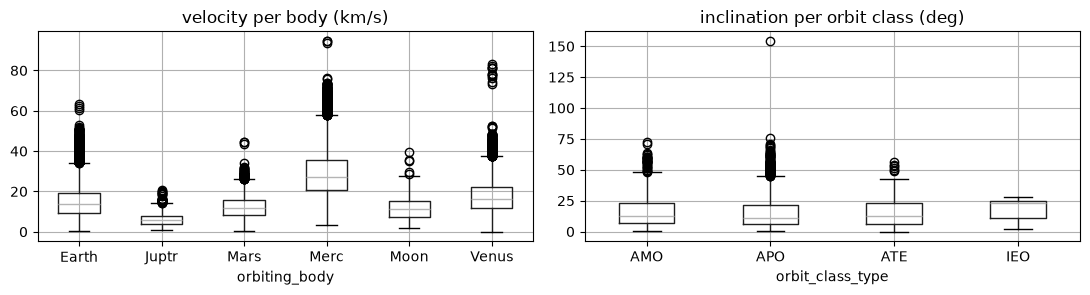

In [26]:
# Look at what was flagged before believing it
print(examples["inclination"][["asteroid_key", "orbit_class_type", "inclination", "z"]].round(2).to_string(index=False))
print()
print(examples["relative_velocity_km_s"][["asteroid_key", "orbiting_body", "close_approach_date", "relative_velocity_km_s", "z"]].round(2).to_string(index=False))
print()
print(examples["semi_major_axis"][["asteroid_key", "orbit_class_type", "semi_major_axis", "eccentricity", "z"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
app.boxplot(column="relative_velocity_km_s", by="orbiting_body", ax=axes[0])
axes[0].set_title("velocity per body (km/s)")
orb.boxplot(column="inclination", by="orbit_class_type", ax=axes[1])
axes[1].set_title("inclination per orbit class (deg)")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Unusual but possible — kept.** The flagged values are real objects. Asteroid key 1357 has a **retrograde** orbit (inclination 154°): it meets the planets
head-on, which is why it also has the fastest Venus passes (83 km/s). Key 3177 has a = 17.8 AU and reaches 34.7 AU from the Sun, far beyond Jupiter.
The 2,502 "low" miss distances are the closest approaches of each body — exactly the events a hazard study cares about. None breaks a rule in section 7.
These are the most interesting asteroids for a hazard study, so the cleaned layer **flags** them (`unusual_high` / `unusual_low`) and keeps the value.

## 10. Findings → draft issues register

| ID | Family | Table.column | What | How many | Evidence (section) | Cause | Proposed decision | Investigated by |
|---|---|---|---|---|---|---|---|---|
| I-01 | Missing | asteroids.designation | NULL; feed records lack the field. 6 more were lost by the M2 loader (fixed in `load.py`) | 33 (was 39) | §2 field table, loss check | **Confirmed** (raw file contents) | keep NULL, flag `missing_not_in_source`; loader fixed | Burak Avşar |
| I-02 | Missing | orbits (whole row) | no orbit for feed-only asteroids | 33 | §2 | **Confirmed** (feed has no `orbital_data`) | keep; asteroid flagged `no_orbit_in_source` | Burak Avşar |
| I-03 | Missing | approaches (whole asteroid) | asteroid has no approach / no Earth approach | 305 / 876 | §2 raw check (326 empty lists) | **Inferred**: orbit never comes close (255 Amor) — MNAR | keep; document for M4 | Burak Avşar |
| I-04 | Missing / coverage | approaches | 56% of rows are future predictions; 1900–2200 window | 84,274 | §1 | **Confirmed** (NASA window) | add `is_prediction` (date > retrieval) | Burak Avşar |
| I-05 | Invalid | approaches.close_approach_date | one date outside 1900–2200 | 1 | §6, §7 | **Inferred**: window edge in UTC | keep, no flag needed | Burak Avşar |
| I-06 | Text | approaches.orbiting_body | abbreviations `Merc`, `Juptr` next to full names | 16,125 rows | §4 | **Confirmed** (NASA codes) | mapping CSV body_alias → full name | Rana |
| I-07 | Text | orbits.orbit_uncertainty | ordered 0–9 code stored as text | 5,000 | §4 | **Confirmed** (NASA uncertainty parameter) | cleaned INTEGER column | Rana |
| I-08 | Identity | asteroids.source_id | same asteroid under a provisional and a numbered id | 3 pairs | §5 | **Inferred** (same designation, H, approach) | mapping CSV, resolve in a view; no merge | Rana |
| I-09 | Cross-field | asteroids.is_potentially_hazardous | label = 1 but H > 22.0 | 15 | §8 | **Inferred** (H refined later); NASA's view unknown | keep label, flag `label_rule_mismatch` | Elif |
| I-10 | Cross-field | approaches.miss_distance_km vs MOID | Earth approach closer than current MOID | 1,603 | §8 | **Inferred** (orbit drifts over centuries) | no flag on value; documented for M4 | Elif |
| I-11 | Cross-field | asteroids.diameter_* | diameter is a function of H, not a measurement | all 5,033 | §3 | **Inferred** (exact √5 ratio) | keep; documented | Elif |
| I-12 | Unusual | orbits / approaches | robust z > 3.5 per group | see §9 | §9 | real objects | flag `unusual_high/low`, keep | Elif |

**Checked and not found:** sentinel values and negatives (§3) · non-NFC / non-ASCII / whitespace / case variants (§4) · date vs epoch vs timestamp mismatch (§6) ·
stuck values in sequence (§6) · 17 physical/definitional rules (§7) · NULL in any key or measurement column except `designation` (§2) · quarantined rows (0, §1).

The *Investigated by* column for I-06 … I-12 is a proposal for the team split; the owners confirm or change it in `docs/cleaning_report.md`.

In [27]:
con.close()